# Tydzień 4: Trening i strojenie modelu (Google Colab)

Projekt: **Automatyczne streszczanie artykułów**. Model: **`facebook/bart-base`** fine-tunowany na CNN/DailyMail.

Notatnik działa w dwóch trybach:
- **w Google Colab** (GPU): pełny trening, strojenie i ewaluacja na zbiorze testowym;
- **lokalnie na Macu**: tryb testowy na kilkudziesięciu przykładach, tylko do sprawdzenia, czy kod działa.

### Przygotowanie 

## K1. Środowisko

In [1]:
import sys
W_COLAB = "google.colab" in sys.modules

if W_COLAB:
    !pip install -q transformers==5.17.0 datasets==5.0.1 evaluate==0.4.6 rouge_score==0.1.2 mlflow nltk

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
import os
import gc
import time
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import nltk
import evaluate
from datasets import load_dataset, Dataset

if W_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    KATALOG = Path("/content/drive/MyDrive/projekt_streszczanie")
else:
    KATALOG = Path("..").resolve()

sys.path.insert(0, str(KATALOG / "src"))
from preprocessing import wyczysc_artykul, wyczysc_streszczenie, filtruj_train

KATALOG_MODELI = KATALOG / "models"
KATALOG_WYNIKOW = KATALOG / "reports"
KATALOG_MODELI.mkdir(parents=True, exist_ok=True)
KATALOG_WYNIKOW.mkdir(parents=True, exist_ok=True)

if torch.cuda.is_available():
    URZADZENIE = "cuda"
    print("GPU:", torch.cuda.get_device_name(0))
elif torch.backends.mps.is_available():
    URZADZENIE = "mps"
    print("GPU: Apple MPS")
else:
    URZADZENIE = "cpu"
    print("Brak GPU! W Colabie włącz: Środowisko wykonawcze → Zmień typ → T4 GPU")

import transformers, datasets
print("transformers", transformers.__version__, "| datasets", datasets.__version__, "| torch", torch.__version__)

Mounted at /content/drive
GPU: Tesla T4
transformers 5.17.0 | datasets 5.0.1 | torch 2.11.0+cu130


## K2. Parametry

W trybie testowym (lokalnie) rozmiary są malutkie, żeby szybko sprawdzić kod. W Colabie używane są pełne wartości.

In [4]:
TRYB_TESTOWY = not W_COLAB

MODEL = "facebook/bart-base"
MAX_INPUT_LENGTH = 1024       # EDA, E3
MAX_TARGET_LENGTH = 128       # EDA, E3
SEED = 42

ROZMIAR_PULI_TRAIN = 64 if TRYB_TESTOWY else 50_000   # tyle tokenizujemy; do treningu bierzemy ROZMIAR_TRAIN (K5)
ROZMIAR_VAL = 16 if TRYB_TESTOWY else 500             # walidacja: strata w trakcie treningu i strojenie generowania
ROZMIAR_TEST = 16 if TRYB_TESTOWY else None           # None = pełny zbiór testowy (11 490)

BATCH_SIZE = 4
AKUMULACJA = 4                # efektywny batch = 4 × 4 = 16
LEARNING_RATE = 5e-5
EPOKI = 1
KROKI_EWALUACJI = 2 if TRYB_TESTOWY else 500          # co ile kroków liczyć stratę walidacyjną i zapisywać checkpoint

NAZWA_EKSPERYMENTU = f"bart-base_lr{LEARNING_RATE}_ep{EPOKI}"
KATALOG_TRENINGU = KATALOG_MODELI / NAZWA_EKSPERYMENTU
print("Tryb testowy:", TRYB_TESTOWY, "| eksperyment:", NAZWA_EKSPERYMENTU)

Tryb testowy: False | eksperyment: bart-base_lr5e-05_ep1


## K3. Dane

Te same kroki co w `03_preprocessing.ipynb`: czyszczenie artykułów, czyszczenie streszczeń w train, filtrowanie train. Dane pobieram z Hugging Face, co w Colabie trwa ok. 1–2 minut.

Żeby zmieścić się w pamięci Colaba (ok. 12 GB RAM), z train **najpierw losuje** nieco więcej przykładów, niż potrzeba (rezerwa na te, które odpadną przy filtrowaniu), a dopiero potem je czyszczę i filtruje. Cały zbiór treningowy w pandas zająłby kilka GB.

In [5]:
ds = load_dataset("abisee/cnn_dailymail", "3.0.0")

# Losujemy z rezerwą 10% na przykłady usunięte przy filtrowaniu (w całym train to ok. 1,1%)
rozmiar_losowania = int(ROZMIAR_PULI_TRAIN * 1.1)
train = ds["train"].shuffle(seed=SEED).select(range(rozmiar_losowania)).to_pandas()
val = ds["validation"].to_pandas()
test = ds["test"].to_pandas()
del ds

for df in [train, val, test]:
    df["article"] = df["article"].map(wyczysc_artykul)
train["highlights"] = train["highlights"].map(wyczysc_streszczenie)
train, raport = filtruj_train(train, val)
print("Filtrowanie:", raport, "| train po filtrowaniu:", len(train))

pula_train = train.head(ROZMIAR_PULI_TRAIN).reset_index(drop=True)
val = val.sample(ROZMIAR_VAL, random_state=SEED).reset_index(drop=True)
if ROZMIAR_TEST:
    test = test.sample(ROZMIAR_TEST, random_state=SEED).reset_index(drop=True)
del train
gc.collect()
print(f"Pula train: {len(pula_train)}, validation: {len(val)}, test: {len(test)}")


README.md:   0%|          | 0.00/15.6k [00:00<?, ?B/s]

3.0.0/train-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  257MB            

3.0.0/train-00000-of-00003.parquet: downloading bytes:           |  0.00B            

3.0.0/train-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  257MB            

3.0.0/train-00001-of-00003.parquet: downloading bytes:           |  0.00B            

...

3.0.0/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/287113 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/13368 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/11490 [00:00<?, ? examples/s]

Filtrowanie: {'powtórzone pary': 123, 'artykuł < 50 słów': 6, 'streszczenie dłuższe niż artykuł': 7, 'wspólne z validation': 0, 'puste streszczenie po czyszczeniu': 0} | train po filtrowaniu: 54864
Pula train: 50000, validation: 500, test: 11490


In [6]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(MODEL)

def tokenizuj(batch):
    wejscie = tokenizer(batch["article"], max_length=MAX_INPUT_LENGTH, truncation=True)
    wejscie["labels"] = tokenizer(text_target=batch["highlights"], max_length=MAX_TARGET_LENGTH, truncation=True)["input_ids"]
    return wejscie

pula_tok = Dataset.from_pandas(pula_train[["article", "highlights"]]).map(tokenizuj, batched=True, remove_columns=["article", "highlights"])
val_tok = Dataset.from_pandas(val[["article", "highlights"]]).map(tokenizuj, batched=True, remove_columns=["article", "highlights"])
print(pula_tok, val_tok, sep="\n")

config.json:   0%|          | 0.00/1.72k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Map:   0%|          | 0/50000 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 50000
})
Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 500
})


## K4. Pomiar czasu na GPU

Tak jak w `03_preprocessing.ipynb` (P10): 20 kroków próbnego treningu. Na Macu krok trwał ok. 9 s.

In [6]:
from transformers import AutoModelForSeq2SeqLM, DataCollatorForSeq2Seq, Seq2SeqTrainingArguments, Seq2SeqTrainer
import tempfile

KROKI_POMIARU = 2 if TRYB_TESTOWY else 20
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL)
pomiar = Seq2SeqTrainer(
    model=model,
    args=Seq2SeqTrainingArguments(
        output_dir=tempfile.mkdtemp(), per_device_train_batch_size=BATCH_SIZE, max_steps=KROKI_POMIARU,
        fp16=(URZADZENIE == "cuda"), report_to="none", save_strategy="no", disable_tqdm=True, seed=SEED,
    ),
    train_dataset=pula_tok.select(range(BATCH_SIZE * KROKI_POMIARU)),
    data_collator=DataCollatorForSeq2Seq(tokenizer, model=model),
    processing_class=tokenizer,
)
start = time.time()
pomiar.train()
s_na_przyklad = (time.time() - start) / (KROKI_POMIARU * BATCH_SIZE)
del model, pomiar
gc.collect()

szacunek = pd.DataFrame({"przykłady": [10_000, 20_000, 30_000, 50_000]})
szacunek["godziny na epokę"] = (szacunek["przykłady"] * s_na_przyklad / 3600).round(2)
print(f"{s_na_przyklad:.3f} s na przykład ({s_na_przyklad * BATCH_SIZE:.2f} s na krok z batchem {BATCH_SIZE})")
szacunek

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/259 [00:00<?, ?it/s]

{'train_runtime': '5.579', 'train_samples_per_second': '14.34', 'train_steps_per_second': '3.585', 'train_loss': '3.382', 'epoch': '1'}
0.074 s na przykład (0.30 s na krok z batchem 4)


,przykłady,godziny na epokę
0,10000,0.21
1,20000,0.41
2,30000,0.62
3,50000,1.03


## K5. Wybór wielkości zbioru treningowego

In [7]:
ROZMIAR_TRAIN = 64 if TRYB_TESTOWY else 50_000

train_tok = pula_tok.select(range(ROZMIAR_TRAIN))
print("Trening na", len(train_tok), "przykładach,", EPOKI, "epoka/i")

Trening na 50000 przykładach, 1 epoka/i


## K6. Trening

- **Strata walidacyjna** liczona co `KROKI_EWALUACJI` kroków pokazuje, czy model się przeucza.
- **Checkpointy** zapisują się na Dysk co `KROKI_EWALUACJI` kroków. 
- **MLflow** zapisuje parametry i krzywe uczenia w `projekt_streszczanie/mlruns`.
- `fp16=True` (tylko na GPU NVIDIA) liczy w połowie precyzji: szybciej i mniej pamięci.

In [9]:
from transformers import AutoModelForSeq2SeqLM, DataCollatorForSeq2Seq, Seq2SeqTrainingArguments, Seq2SeqTrainer
from transformers.trainer_utils import get_last_checkpoint

try:
    import mlflow
    os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"
    os.environ["MLFLOW_TRACKING_URI"] = (KATALOG / "mlruns").as_uri()
    os.environ["MLFLOW_EXPERIMENT_NAME"] = "streszczanie-bart"
    RAPORTOWANIE = "mlflow"
except ImportError:
    RAPORTOWANIE = "none"
    print("Brak mlflow, logi tylko w notatniku")

model = AutoModelForSeq2SeqLM.from_pretrained(MODEL)
argumenty = Seq2SeqTrainingArguments(
    output_dir=str(KATALOG_TRENINGU),
    run_name=NAZWA_EKSPERYMENTU,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE * 2,
    gradient_accumulation_steps=AKUMULACJA,
    learning_rate=LEARNING_RATE,
    num_train_epochs=EPOKI,
    warmup_steps=0.05,             # 5% kroków na rozgrzewkę (liczba < 1 = ułamek wszystkich kroków)
    weight_decay=0.01,
    fp16=(URZADZENIE == "cuda"),
    eval_strategy="steps",
    eval_steps=KROKI_EWALUACJI,
    save_strategy="steps",
    save_steps=KROKI_EWALUACJI,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    logging_steps=1 if TRYB_TESTOWY else 50,
    report_to=RAPORTOWANIE,
    seed=SEED,
)
trener = Seq2SeqTrainer(
    model=model,
    args=argumenty,
    train_dataset=train_tok,
    eval_dataset=val_tok,
    data_collator=DataCollatorForSeq2Seq(tokenizer, model=model),
    processing_class=tokenizer,
)

ostatni_checkpoint = get_last_checkpoint(str(KATALOG_TRENINGU)) if KATALOG_TRENINGU.exists() else None
print("Wznawiam od:", ostatni_checkpoint or "początku")
start = time.time()
trener.train(resume_from_checkpoint=ostatni_checkpoint)
print(f"Czas treningu: {(time.time() - start) / 60:.1f} min")

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/259 [00:00<?, ?it/s]

Wznawiam od: /content/drive/MyDrive/projekt_streszczanie/models/bart-base_lr5e-05_ep1/checkpoint-3125


[transformers] There were missing keys in the checkpoint model loaded: ['model.encoder.embed_tokens.weight', 'model.decoder.embed_tokens.weight', 'lm_head.weight'].
[transformers] There were missing keys in the checkpoint model loaded: ['model.encoder.embed_tokens.weight', 'model.decoder.embed_tokens.weight', 'lm_head.weight'].


Step,Training Loss,Validation Loss


Czas treningu: 0.8 min


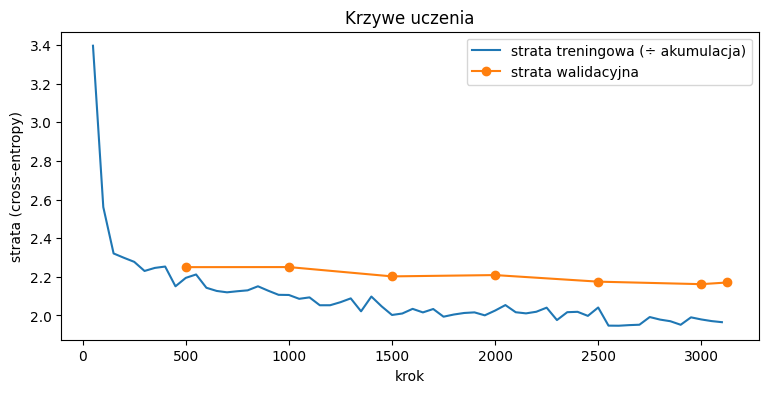

In [10]:
historia = pd.DataFrame(trener.state.log_history)
strata_train = historia.dropna(subset=["loss"])[["step", "loss"]]
strata_val = historia.dropna(subset=["eval_loss"])[["step", "eval_loss"]]

plt.figure(figsize=(9, 4))
plt.plot(strata_train["step"], strata_train["loss"] / AKUMULACJA, label="strata treningowa (÷ akumulacja)")
plt.plot(strata_val["step"], strata_val["eval_loss"], "o-", label="strata walidacyjna")
plt.title("Krzywe uczenia")
plt.xlabel("krok")
plt.ylabel("strata (cross-entropy)")
plt.legend()
plt.savefig(KATALOG_WYNIKOW / f"krzywe_uczenia_{NAZWA_EKSPERYMENTU}.png", dpi=100, bbox_inches="tight")
plt.show()

In [11]:
KATALOG_NAJLEPSZEGO = KATALOG_MODELI / f"{NAZWA_EKSPERYMENTU}_najlepszy"
trener.save_model(str(KATALOG_NAJLEPSZEGO))
tokenizer.save_pretrained(str(KATALOG_NAJLEPSZEGO))
print("Model zapisany:", KATALOG_NAJLEPSZEGO)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model zapisany: /content/drive/MyDrive/projekt_streszczanie/models/bart-base_lr5e-05_ep1_najlepszy


## K7. Ewaluacja na walidacji

Porównuje model z Lead-3 na tych samych artykułach walidacyjnych. Parametry generowania na start są takie jak w `bart-large-cnn`.

In [12]:
nltk.download("punkt_tab", quiet=True)
rouge = evaluate.load("rouge")
model = trener.model.to(URZADZENIE).eval()

def generuj(artykuly, batch=8, **parametry):
    """Generuje streszczenia dla listy artykułów."""
    wyniki = []
    for i in range(0, len(artykuly), batch):
        wejscie = tokenizer(artykuly[i:i + batch], max_length=MAX_INPUT_LENGTH, truncation=True,
                            padding=True, return_tensors="pt").to(URZADZENIE)
        with torch.no_grad():
            wyjscie = model.generate(**wejscie, **parametry)
        wyniki += tokenizer.batch_decode(wyjscie, skip_special_tokens=True)
    return wyniki

def policz_rouge(predykcje, referencje):
    pred = ["\n".join(nltk.sent_tokenize(p)) for p in predykcje]
    ref = ["\n".join(nltk.sent_tokenize(r)) for r in referencje]
    wynik = rouge.compute(predictions=pred, references=ref, use_stemmer=True)
    return {k: round(v * 100, 2) for k, v in wynik.items()}

PARAMETRY_STARTOWE = dict(num_beams=4, length_penalty=2.0, no_repeat_ngram_size=3, min_length=30, max_new_tokens=MAX_TARGET_LENGTH)

lead3_val = ["\n".join(nltk.sent_tokenize(a)[:3]) for a in val["article"]]
start = time.time()
pred_val = generuj(val["article"].tolist(), **PARAMETRY_STARTOWE)
print(f"Generowanie {len(val)} streszczeń: {time.time() - start:.0f} s")

pd.DataFrame({
    "Lead-3": policz_rouge(lead3_val, val["highlights"]),
    "bart-base (fine-tuning)": policz_rouge(pred_val, val["highlights"]),
})

Generowanie 500 streszczeń: 169 s


,Lead-3,bart-base (fine-tuning)
rouge1,40.68,42.10
rouge2,18.14,19.55
rougeL,25.16,28.58
rougeLsum,37.24,39.16


In [13]:
for i in range(2):
    print("ARTYKUŁ:", val["article"][i][:300], "...")
    print("\nREDAKCJA:", val["highlights"][i])
    print("\nMODEL:", pred_val[i])
    print("=" * 100)

ARTYKUŁ: A woman has sparked uproar on social media after enthusiastically bearing her K-cup breasts on Google Street View. Karen Davis from Port Pirie in South Australia was captured streaking by the Google camera cars for the popular Google Maps app, which allows users to zoom in on certain streets and tow ...

REDAKCJA: A woman has caused a social media storm after bearing her boobs .
The Port Pirie woman showed her size-K assets on Google Street View .
She has been called a 'bad mother' by people from her town .
Karen Davis says they are 'not happy with their own bodies'
She plans to do a topless skydive for her 40th birthday next year .

MODEL: Karen Davis from Port Pirie in South Australia was captured streaking by the Google camera cars for the popular Google Maps app.
The 38-year-old mother, who plans to skydive topless for her 40th birthday, has hit back at 'flat-tittie chicks' claiming they are not confident enough with their own bodies and should focus on how they look.
Ms D

In [14]:
import re
artykul = val["article"][0]
for m in re.finditer(r"\d+-year-old|40th|birthday", artykul):
    print("...", artykul[max(0, m.start() - 80): m.end() + 80], "...")


... eets and towns in cities all over the world with a 360-degree view. However the 38-year-old mother, who plans to skydive topless for her 40th birthday, has hit back at 'fl ...
... gree view. However the 38-year-old mother, who plans to skydive topless for her 40th birthday, has hit back at 'flat-tittie chicks' claiming they are not confident  ...
... view. However the 38-year-old mother, who plans to skydive topless for her 40th birthday, has hit back at 'flat-tittie chicks' claiming they are not confident enough wi ...
... s and is finally ready to embrace them and she plans to skydive topless for her 40th birthday . 'All the flat-tittie chicks think I am disgusting. Big-boob envy has ...
...  is finally ready to embrace them and she plans to skydive topless for her 40th birthday . 'All the flat-tittie chicks think I am disgusting. Big-boob envy has hit Port ...


Na 500 artykułach walidacyjnych model pobija Lead-3 we wszystkich metrykach (ROUGE-2: 19,55 vs 18,14, czyli +1,41). Streszczenia są płynne i mają format punktów jak u redakcji, bez spacji przed kropką (efekt czyszczenia z tygodnia 3). Model często przepisuje prawie dosłownie zdania z początku artykułu, co pasuje do lead bias z EDA. Szczegóły, które wyglądały na halucynację (wiek „38-year-old”), okazały się wiernym cytatem z artykułu.

## K8. Strojenie parametrów generowania

Parametry generowania zmieniam bez ponownego treningu, więc strojenie jest tanie. Sprawdzam kilka kombinacji na walidacji i wybieram najlepszą według ROUGE-2 (metryka główna).

- `num_beams`: ile wariantów streszczenia model rozważa naraz (beam search).
- `length_penalty`: > 1 sprzyja dłuższym streszczeniom, < 1 krótszym.
- `no_repeat_ngram_size=3`: zakazuje powtarzania tej samej trójki słów.

In [15]:
siatka = [
    dict(num_beams=2, length_penalty=1.0),
    dict(num_beams=4, length_penalty=1.0),
    dict(num_beams=4, length_penalty=2.0),
    dict(num_beams=6, length_penalty=2.0),
]

wyniki_strojenia = []
for zmiany in siatka:
    parametry = {**PARAMETRY_STARTOWE, **zmiany}
    start = time.time()
    pred = generuj(val["article"].tolist(), **parametry)
    wynik = policz_rouge(pred, val["highlights"])
    wynik.update(zmiany)
    wynik["średnia długość (słowa)"] = round(np.mean([len(p.split()) for p in pred]), 1)
    wynik["czas (s)"] = round(time.time() - start)
    wyniki_strojenia.append(wynik)
    print(zmiany, "→ ROUGE-2:", wynik["rouge2"])

strojenie = pd.DataFrame(wyniki_strojenia).sort_values("rouge2", ascending=False)
strojenie.to_csv(KATALOG_WYNIKOW / f"strojenie_generowania_{NAZWA_EKSPERYMENTU}.csv", index=False)
strojenie

{'num_beams': 2, 'length_penalty': 1.0} → ROUGE-2: 19.51
{'num_beams': 4, 'length_penalty': 1.0} → ROUGE-2: 19.6
{'num_beams': 4, 'length_penalty': 2.0} → ROUGE-2: 19.55
{'num_beams': 6, 'length_penalty': 2.0} → ROUGE-2: 19.22


,rouge1,rouge2,rougeL,rougeLsum,num_beams,length_penalty,średnia długość (słowa),czas (s)
1,41.86,19.60,28.67,38.91,4,1.0,58.6,170
2,42.10,19.55,28.58,39.16,4,2.0,62.8,170
0,41.78,19.51,28.35,38.98,2,1.0,58.3,148
3,41.78,19.22,28.19,38.81,6,2.0,63.0,222


In [16]:
najlepsze = strojenie.iloc[0]
PARAMETRY_NAJLEPSZE = {**PARAMETRY_STARTOWE,
                       "num_beams": int(najlepsze["num_beams"]),
                       "length_penalty": float(najlepsze["length_penalty"])}
print("Najlepsze parametry generowania:", PARAMETRY_NAJLEPSZE)

if RAPORTOWANIE == "mlflow":
    with mlflow.start_run(run_name=f"{NAZWA_EKSPERYMENTU}_generowanie"):
        mlflow.log_params({f"gen_{k}": v for k, v in PARAMETRY_NAJLEPSZE.items()})
        mlflow.log_metrics({f"val_{k}": float(najlepsze[k]) for k in ["rouge1", "rouge2", "rougeLsum"]})

Najlepsze parametry generowania: {'num_beams': 4, 'length_penalty': 1.0, 'no_repeat_ngram_size': 3, 'min_length': 30, 'max_new_tokens': 128}


Najlepsze parametry: num_beams=4, length_penalty=1.0 (ROUGE-2 = 19,60 na walidacji). Różnice między ustawieniami są małe (19,22–19,60), więc model jest mało wrażliwy na parametry generowania. Wyższy length_penalty wydłuża streszczenia (58,6 → 62,8 słowa) i lekko podnosi ROUGE-1 oraz Lsum, ale nie ROUGE-2. num_beams=6 dało najgorszy wynik i było o 30% wolniejsze.

## K9. Ewaluacja na zbiorze testowym

Pełny zbiór testowy (11 490 artykułów). W Colabie na GPU T4 zwykle trwa to kilkadziesiąt minut. Predykcje zapisują się na Dysk, żeby nie generować ich drugi raz.

In [17]:
plik_predykcji = KATALOG_WYNIKOW / f"predykcje_test_{NAZWA_EKSPERYMENTU}.parquet"

if plik_predykcji.exists() and not TRYB_TESTOWY:
    pred_test = pd.read_parquet(plik_predykcji)["predykcja"].tolist()
    print("Wczytano zapisane predykcje")
else:
    start = time.time()
    pred_test = generuj(test["article"].tolist(), **PARAMETRY_NAJLEPSZE)
    print(f"Generowanie {len(test)} streszczeń: {(time.time() - start) / 60:.1f} min")
    puste = sum(1 for p in pred_test if not p.strip())
    assert puste == 0, f"{puste} pustych streszczeń: prawdopodobnie zabrakło pamięci GPU. Zmniejsz batch w generuj()"
    pd.DataFrame({"id": test["id"], "predykcja": pred_test}).to_parquet(plik_predykcji, index=False)

wynik_test = policz_rouge(pred_test, test["highlights"])

tabela = pd.DataFrame({
    "Lead-3 (zmierzony)": {"rouge1": 40.05, "rouge2": 17.49, "rougeLsum": 36.38},
    "bart-base (mój model)": {k: wynik_test[k] for k in ["rouge1", "rouge2", "rougeLsum"]},
    "bart-large-cnn (literatura)": {"rouge1": 44.16, "rouge2": 21.28, "rougeLsum": 40.90},
})
tabela.to_csv(KATALOG_WYNIKOW / f"wyniki_test_{NAZWA_EKSPERYMENTU}.csv")

r2 = wynik_test["rouge2"]
print(f"ROUGE-2 = {r2}:", "✅ cel (≥ 19,01)" if r2 >= 19.01 else "✅ minimum (> 17,49)" if r2 > 17.49 else "❌ poniżej Lead-3")
print(f"Odrobiono {(r2 - 17.49) / (21.28 - 17.49):.0%} różnicy między Lead-3 a bart-large-cnn")
tabela

Generowanie 11490 streszczeń: 63.3 min
ROUGE-2 = 18.64: ✅ minimum (> 17,49)
Odrobiono 30% różnicy między Lead-3 a bart-large-cnn


,Lead-3 (zmierzony),bart-base (mój model),bart-large-cnn (literatura)
rouge1,40.05,41.05,44.16
rouge2,17.49,18.64,21.28
rougeLsum,36.38,37.99,40.90


In [18]:
if RAPORTOWANIE == "mlflow":
    with mlflow.start_run(run_name=f"{NAZWA_EKSPERYMENTU}_test"):
        mlflow.log_params({"rozmiar_train": ROZMIAR_TRAIN, "epoki": EPOKI, "learning_rate": LEARNING_RATE})
        mlflow.log_metrics({f"test_{k}": v for k, v in wynik_test.items()})

## K10. Wnioski

**Pomiar czasu (K4)**
- GPU: Tesla T4, czas na przykład: 0,074 s (na Macu ok. 2,2 s), czyli ok. 30 razy szybciej.
- Wybrany rozmiar treningu: 50 000 przykładów, 1 epoka (~1 h według szacunku, w praktyce 43 min). Wykorzystanie całej przygotowanej puli przy czasie mieszczącym się w jednej darmowej sesji Colaba, z zapasem na strojenie i ewaluację. Więcej różnych przykładów zwykle daje więcej niż kolejna epoka na tych samych danych.

**Trening (K6)**
- Czas treningu: 43,2 min (3125 kroków, efektywny batch 16).
- Strata treningowa spadła gwałtownie z 3,4 do ~2,3 w pierwszych 150 krokach (model uczy się formatu streszczeń), a potem łagodnie do ~1,97. Strata walidacyjna spadła z 2,25 do ~2,16.
- Odstęp między krzywymi (~0,2) nie rośnie, więc model się nie przeucza. Krzywa walidacyjna wciąż lekko opada, więc kolejna epoka mogłaby dać niewielką poprawę.
- Najlepszy checkpoint (najniższa strata walidacyjna): krok 3000.
- Uwaga techniczna: przy akumulacji gradientu transformers loguje sumę strat z 4 małych batchy, dlatego na wykresie strata treningowa jest podzielona przez AKUMULACJA.

**Ewaluacja na walidacji (K7)**
- Na 500 artykułach walidacyjnych model pobija Lead-3 we wszystkich metrykach (ROUGE-2: 19,55 vs 18,14, czyli +1,41).
- Streszczenia są płynne i mają format punktów jak u redakcji, bez spacji przed kropką (efekt czyszczenia z tygodnia 3).
- Model często przepisuje prawie dosłownie zdania z początku artykułu, co pasuje do lead bias z EDA. Szczegóły, które wyglądały na halucynację (wiek „38-year-old”), okazały się wiernym cytatem z artykułu.

**Strojenie generowania (K8)**
- Najlepsze parametry: num_beams=4, length_penalty=1.0 (ROUGE-2 = 19,60 na walidacji).
- Różnice między ustawieniami są małe (19,22–19,60), więc model jest mało wrażliwy na parametry generowania. O jakości zdecydował głównie trening.
- Wyższy length_penalty wydłuża streszczenia (58,6 → 62,8 słowa) i lekko podnosi ROUGE-1 oraz Lsum, ale nie ROUGE-2.
- num_beams=6 dało najgorszy wynik (19,22) i było o 30% wolniejsze.

**Wynik na teście (K9)**
- Generowanie 11 490 streszczeń: 63,3 min.
- ROUGE-1 / 2 / Lsum: 41,05 / 18,64 / 37,99.
- Minimum osiągnięte: model pobija Lead-3 we wszystkich metrykach, w ROUGE-2 o 1,15 punktu.
- Cel projektu (ROUGE-2 ≥ 19,01) nieosiągnięty: brakuje 0,37 punktu. Model odrobił 30% różnicy między Lead-3 a bart-large-cnn (cel: 40%).
- Na walidacji przewaga nad Lead-3 była większa (+1,41 vs +1,15 na teście), bo na tych samych 500 artykułach wybierano checkpoint i parametry generowania. Wynik testowy jest oceną uczciwą.
- Możliwe dalsze kroki: druga epoka (strata walidacyjna wciąż lekko spadała) albo trening na większej części zbioru (użyto 50 tys. z 284 tys. przykładów).
